# Linear Regression from Scratch

This project implements a Linear Regression model from scratch using Python and NumPy, without relying on machine learning libraries such as Scikit-learn.

The goal is to understand how linear regression works internally, including prediction, error measurement, gradient descent, model training, evaluation, and feature scaling.

**Technologies used:**
- Python
- NumPy
- Matplotlib
- Jupyter Notebook

**Dataset:** A small, artificially created dataset containing house sizes (m²) and their corresponding prices (€).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## 1. Dataset Exploration

In this section, we explore our dataset to understand the relationship between house sizes and their prices.

Our dataset contains two variables:

- **Feature (x):** The size of a house, measured in square meters (m²).
- **Target (y):** The price of a house, measured in euros (€).

Before building our model, we examine the dataset using basic statistical measurements.

### Mean

The mean represents the average value of a dataset. We calculate the average house size and average house price to understand the central values of our data.

### Standard Deviation

Standard deviation measures how spread out the values are relative to their mean. A larger standard deviation indicates greater variation in the data.

### Correlation

Correlation measures the strength and direction of the linear relationship between two variables. Its value ranges from -1 to +1:

- **+1:** Perfect positive correlation.
- **0:** No linear correlation.
- **-1:** Perfect negative correlation.

We use these measurements to better understand our data before implementing the linear regression model.

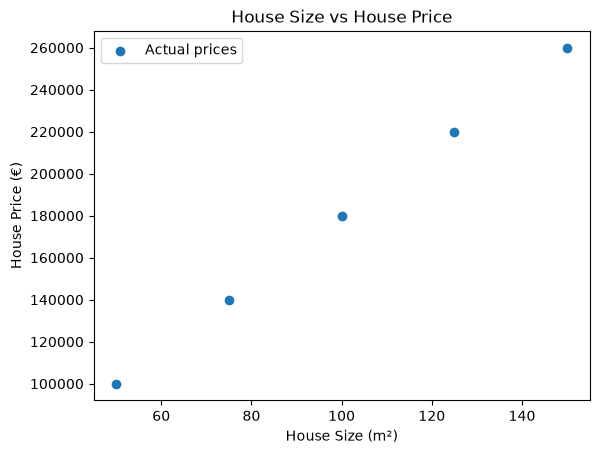

Number of houses: 5
Average house size: 100.0 m²
Average house price: €180000.0


In [2]:
x = np.array([50, 75, 100, 125, 150])
y = np.array([100000, 140000, 180000, 220000, 260000])

plt.scatter(x, y, label="Actual prices")
plt.xlabel("House Size (m²)")
plt.ylabel("House Price (€)")
plt.title("House Size vs House Price")
plt.legend()
plt.savefig("images/dataset.png", dpi=300, bbox_inches="tight")
plt.show()


print('Number of houses:', x.size)

mean_size = np.mean(x)
mean_price = np.mean(y)

print('Average house size:', mean_size, 'm²')
print('Average house price:', '€' + str(mean_price))

### Standard deviation

In [3]:
std_size = np.std(x)
std_price = np.std(y)

print('House size standard deviation:', f'{std_size:.2f}', 'm²')
print('House price standard deviation:', '€' + f'{std_price:.2f}')

House size standard deviation: 35.36 m²
House price standard deviation: €56568.54


### Correlation

In [4]:
corr_mat = np.corrcoef(x, y)
corr = corr_mat[0, 1]

print('Correlation:', corr)

Correlation: 1.0


## 2. Building the Prediction Function

### Experimenting with Parameters

Before training the model, we experiment with different weight and bias values to observe how they affect predictions.

This helps us understand how changing the parameters moves and adjusts the regression line.

### Visualizing Predictions

We plot the predicted values alongside the actual data points to visually compare how well different parameter combinations represent the relationship between house size and price.
### Creating the Prediction Function

Linear regression is a supervised machine learning algorithm that attempts to model the relationship between an input feature and a target variable using a straight line.

The mathematical equation for simple linear regression is:

$$
ŷ = wx + b
$$

Where:

- **x:** The input feature (house size).
- **ŷ:** The predicted house price.
- **w (weight):** Determines the slope of the regression line and how much the prediction changes when the input increases.
- **b (bias):** Determines where the regression line intersects the y-axis.

We implement this equation using a Python function that takes the input feature, weight, and bias and returns a predicted value.

In [5]:
def predict(x, w, b):
    return w * x + b

### Experimenting with Parameters

In [6]:
print('Actual prices:', y)
print('House prices experiment 1:', predict(x, 1000, 30000))
print('House prices experiment 2:', predict(x, 1500, 20000))

Actual prices: [100000 140000 180000 220000 260000]
House prices experiment 1: [ 80000 105000 130000 155000 180000]
House prices experiment 2: [ 95000 132500 170000 207500 245000]


### Visualizing Predictions

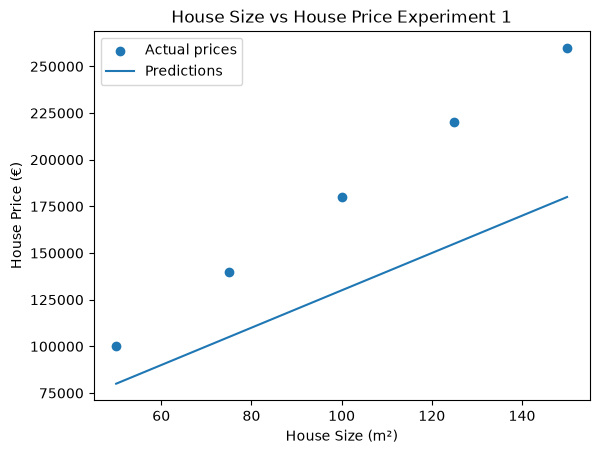

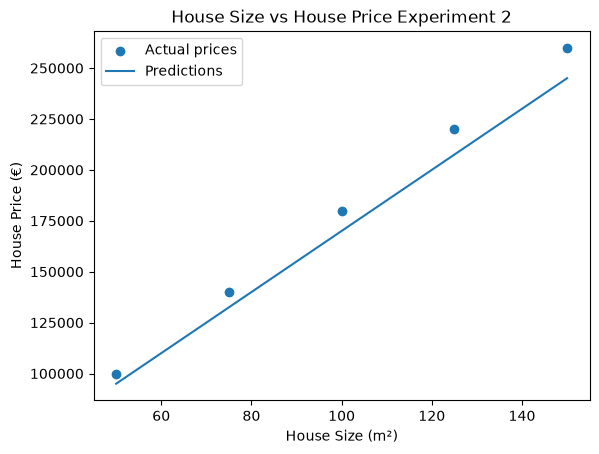

In [7]:
plt.scatter(x, y, label="Actual prices")
plt.plot(x, predict(x, 1000, 30000), label="Predictions")
plt.xlabel("House Size (m²)")
plt.ylabel("House Price (€)")
plt.title("House Size vs House Price Experiment 1")
plt.legend()
plt.show()

plt.scatter(x, y, label="Actual prices")
plt.plot(x, predict(x, 1500, 20000), label="Predictions")
plt.xlabel("House Size (m²)")
plt.ylabel("House Price (€)")
plt.title("House Size vs House Price Experiment 2")
plt.legend()
plt.show()

## 3. Measuring Prediction Errors

A prediction is not necessarily equal to the actual target value. To evaluate how well our model performs, we need a way to measure the difference between its predictions and the actual values.

### Prediction Error (Residual)

The prediction error, also called the residual, is the difference between the actual value and the predicted value:

$$
Error = y - ŷ
$$

A positive error means the model underestimated the actual value, while a negative error means it overestimated it.

### Mean Squared Error (MSE)

Mean Squared Error is a common metric used to measure the performance of regression models.

It calculates the average of the squared differences between actual and predicted values:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-ŷ_i)^2
$$

Where:

- **n:** Number of data points.
- **y:** Actual value.
- **ŷ:** Predicted value.

We square the errors to prevent positive and negative errors from cancelling each other out and to penalize larger errors more heavily.

A lower MSE indicates better predictions when comparing models on the same dataset.

We use MSE to compare different weight and bias combinations and identify which produces the most accurate predictions.

Since we square the prediction errors, MSE is expressed in squared units. In our project, this means euros squared (€²).

### Create an MSE function

In [8]:
def calculate_mse(actual, pred):
    return np.mean((actual - pred) ** 2)

### Evaluate the two experiments

In [9]:
print('MSE experiment 1:', calculate_mse(y, predict(x, 1000, 30000)))
print('MSE experiment 2:', calculate_mse(y, predict(x, 1500, 20000)))

MSE experiment 1: 2950000000.0
MSE experiment 2: 112500000.0


### Compare the results

In [10]:
if calculate_mse(y, predict(x, 1000, 30000)) < calculate_mse(y, predict(x, 1500, 20000)):
    print('Experiment 1 has lower MSE')
else:
    print('Experiment 2 has lower MSE')

Experiment 2 has lower MSE


### Experiment further

In [11]:
print('MSE experiment 3:', calculate_mse(y, predict(x, 2000, 0)))

if calculate_mse(y, predict(x, 1500, 20000)) < calculate_mse(y, predict(x, 2000, 0)):
    print('Experiment 2 has lower MSE')
else:
    print('Experiment 3 has lower MSE')

MSE experiment 3: 600000000.0
Experiment 2 has lower MSE


## 4. Gradient Descent

So far, we have experimented with different weight and bias values manually. However, manually searching for the best parameters is inefficient.

Gradient Descent is an optimization algorithm that automatically adjusts the model's parameters to minimize prediction errors.

It works by calculating the gradients of the loss function and updating the weight and bias in the direction that reduces the error.

### The Loss Function

We use Mean Squared Error (MSE) as our loss function:

$$
J(w,b) = \frac{1}{n}\sum_{i=1}^{n}(wx_i+b-y_i)^2
$$

The loss function measures the average squared prediction error for the current values of the weight and bias. Gradient descent attempts to minimize this function by repeatedly updating these parameters.

The objective is to find values of w and b that minimize this function.

### Calculating Gradients

A gradient indicates how much the loss function changes when a parameter changes.

We calculate two partial derivatives:

**Gradient with respect to the weight:**

$$
\frac{\partial J}{\partial w}
=
\frac{2}{n}\sum_{i=1}^{n}x_i(\hat{y}_i-y_i)
$$

**Gradient with respect to the bias:**

$$
\frac{\partial J}{\partial b}
=
\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
$$

These gradients tell us how to adjust each parameter to reduce the loss.

### Updating the Parameters

We update the weight and bias using the following equations:

$$
w_{\text{new}} = w_{\text{old}}-\alpha\frac{\partial J}{\partial w}
$$

$$
b_{\text{new}} = b_{\text{old}}-\alpha\frac{\partial J}{\partial b}
$$

Here, **α (alpha)** represents the learning rate, which controls the size of each update.

A learning rate that is too small can make training very slow, while one that is too large can cause the model to overshoot the minimum or fail to converge.

In this section, we implement gradient calculations and perform an initial parameter update.

### Calculate the gradients

We create a function that calculates the partial derivatives of the loss function with respect to the weight and bias.

The function uses the current predictions and actual values to calculate both gradients, which will later be used to update the model's parameters.

In [12]:
def calculate_gradients(x, y, w, b):
    y_pred = predict(x, w, b)
    err = y_pred - y
    d_w = 2 * np.mean(x * err)
    d_b = 2 * np.mean(err)

    return d_w, d_b

### Perform one gradient descent update

Before automating the training process, we perform one gradient descent update manually.

We initialize the weight and bias to zero, calculate their gradients, and update both parameters using the selected learning rate.

We then compare the MSE before and after the update to observe whether the prediction error has decreased.

In [13]:
w = 0
b = 0
learning_rate = 0.000001

print('Old parameters:', 'w =', w, 'b =', b)
print('Old MSE:', calculate_mse(y, predict(x, w, b)))

d_w, d_b = calculate_gradients(x, y, w, b)
w -= learning_rate * d_w
b -= learning_rate * d_b

print('New parameters:', 'w =', w, 'b =', b)
print('New MSE:', calculate_mse(y, predict(x, w, b)))

Old parameters: w = 0 b = 0
Old MSE: 35600000000.0
New parameters: w = 40.0 b = 0.36
New MSE: 34017873280.1296


## 5. Automating Gradient Descent

Performing gradient descent one update at a time would be impractical for a machine learning model.

To solve this, we create a training function that repeatedly performs the following steps:

1. Calculate the gradients using the current weight and bias.
2. Update the weight and bias using the learning rate.
3. Calculate and store the new MSE.

This process is repeated for a specified number of iterations.

At the end of training, the function returns the optimized weight, bias, and loss history.

### Training the Model

We initialize the model's parameters and define the learning rate and number of iterations.

The training function then uses these settings to optimize the model automatically.
### Creating the Training Function

In [14]:
def train_linear_regression(x, y, w, b, learning_rate, iterations):
    loss_history = []

    for _ in range(iterations):
        d_w, d_b = calculate_gradients(x, y, w, b)
        w, b = w - learning_rate * d_w, b - learning_rate * d_b
        loss_history.append(calculate_mse(y, predict(x, w, b)))

    return w, b, loss_history

initial_w = 0
initial_b = 0
learning_rate = 0.000001
iterations = 1000

print('MSE before training:', calculate_mse(y, predict(x, initial_w, initial_b)))

w, b, mse = train_linear_regression(x, y, initial_w, initial_b, learning_rate, iterations)

print('Trained parameters:', 'w =', w, 'b =', b, ',' , 'Final MSE:', mse[-1])

MSE before training: 35600000000.0
Trained parameters: w = 1777.5996071962722 b = 20.241481603856304 , Final MSE: 44354527.86275721


## 6. Visualizing the Learning Process

Visualizing the training process helps us understand how the model improves as gradient descent updates its parameters.

We use two visualizations to examine the results.

### Plotting the Loss Curve

The loss curve shows how the Mean Squared Error changes over the training iterations.

A decreasing loss indicates that the model is learning and improving its predictions.

Ideally, the loss gradually decreases and eventually stabilizes as the model approaches a minimum.

### Plotting the Regression Line

We plot the trained regression line alongside the original data points.

This allows us to visually evaluate how well the model represents the relationship between house size and house price.

### Plot the loss curve

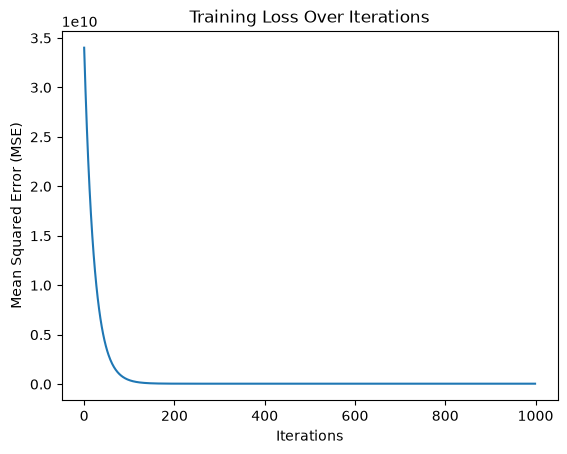

In [15]:
plt.plot(mse)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Training Loss Over Iterations')
plt.savefig("images/loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### Plot the regression line

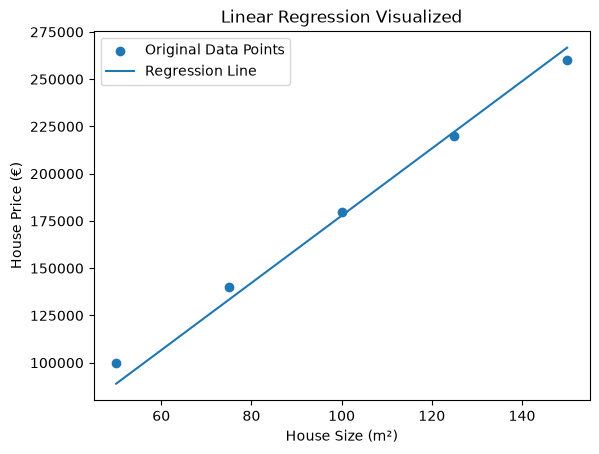

In [16]:
plt.scatter(x, y, label='Original Data Points')
plt.plot(x, predict(x, w, b), label='Regression Line')
plt.xlabel('House Size (m²)')
plt.ylabel('House Price (€)')
plt.title('Linear Regression Visualized')
plt.legend()
plt.savefig("images/regression_line.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Testing on Unseen Data

A machine learning model should not only perform well on the data used during training. It should also be able to make accurate predictions on data it has not previously encountered.

To evaluate this, we split our dataset into two parts:

- **Training data:** Used to train the model and optimize its parameters.
- **Testing data:** Used to evaluate the model's performance on an unseen example.

We train a new model using the training data and then use it to predict the price of a house from the testing data.

Finally, we compare the predicted price with the actual price and calculate the test MSE.

This provides a basic demonstration of how a model can be evaluated on unseen data.

**Note:** Our dataset is very small, so this test is useful for learning but is not sufficient to reliably measure real-world performance.

### Train a new model

We separate the final data point from the dataset and use the remaining observations for training.

We initialize a new model and train it using only the training data.

In [17]:
x_train, y_train, x_test, y_test = x[:-1], y[:-1], x[-1], y[-1]
w = 0
b = 0
learning_rate = 0.000001
iterations = 1000
w, b, loss = train_linear_regression(x_train, y_train, w, b, learning_rate, iterations)

### Evaluate the model

After training, we use the model to predict the house price for the unseen test example.

We compare the prediction with the actual price and calculate the Mean Squared Error to measure the prediction error.

In [18]:
print('Predicted price:', predict(x_test, w, b))
print('Actual price:', y_test)
print('Prediction error:', predict(x_test, w, b) - y_test)
print('MSE:', calculate_mse(y_test, predict(x_test, w, b)))

Predicted price: 271098.97378641495
Actual price: 260000
Prediction error: 11098.97378641495
MSE: 123187219.11152622


## 8. Feature Scaling and Normalization

Feature scaling is a preprocessing technique that transforms numerical features into a more consistent range.

It is particularly useful for optimization algorithms such as Gradient Descent because features with very different scales can make optimization more difficult.

### Standardization

In this project, we use standardization to transform our input feature.

Standardization subtracts the mean from each value and divides the result by the standard deviation:

$$
x_{\text{scaled}} = \frac{x-\mu}{\sigma}
$$

Where:

- **x:** Original feature value.
- **μ (mu):** Mean of the feature.
- **σ (sigma):** Standard deviation of the feature.
- **x_scaled:** Standardized feature value.

After standardization, the transformed feature has a mean close to zero and a standard deviation close to one.

### Demonstrating Standardization

For this demonstration, we calculate the mean and standard deviation using the entire dataset.

When preparing data for model training and evaluation, we calculate these statistics using only the training data to avoid data leakage.

In [19]:
x_scaled = (x - mean_size) / std_size

### Verify the result

In [20]:
print('Original data:', x)
print('Standardized data:', x_scaled)
print('Scaled mean:', np.mean(x_scaled))
print('Scaled standard deviation:', np.std(x_scaled))

Original data: [ 50  75 100 125 150]
Standardized data: [-1.41421356 -0.70710678  0.          0.70710678  1.41421356]
Scaled mean: 0.0
Scaled standard deviation: 0.9999999999999999


### Visualize the transformation

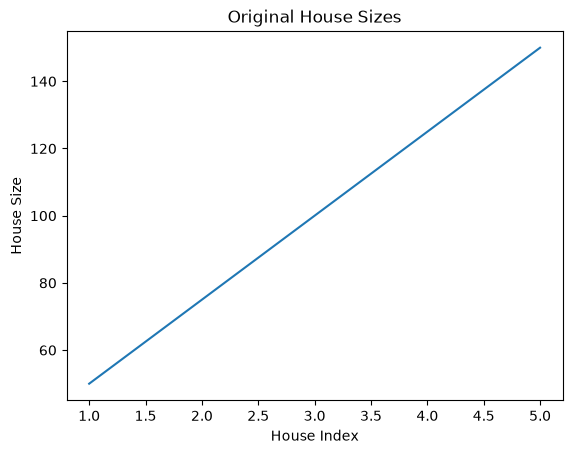

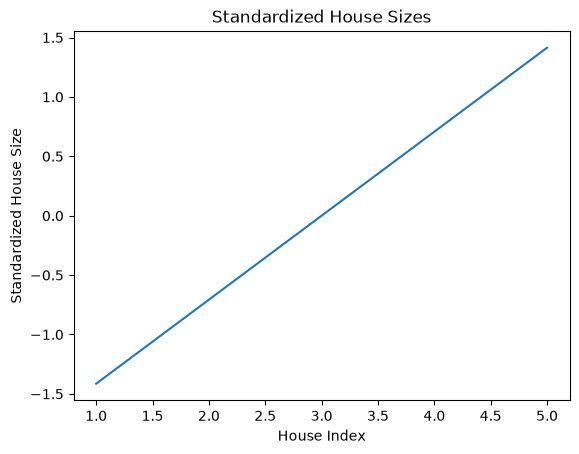

In [21]:
plt.plot(np.arange(1, len(x) + 1), x)
plt.xlabel('House Index')
plt.ylabel('House Size')
plt.title('Original House Sizes')
plt.show()

plt.plot(np.arange(1, len(x) + 1), x_scaled)
plt.xlabel('House Index')
plt.ylabel('Standardized House Size')
plt.title('Standardized House Sizes')
plt.show()

### Avoiding Data Leakage

When preparing training and testing data, we calculate the mean and standard deviation using only the training data.

We then use these same statistics to transform both the training and testing features.

This prevents information from the test set from influencing the preprocessing of the training data.

### Train using standardized features
We train another linear regression model using the standardized training features.

We then evaluate it using the standardized test feature and compare its prediction with the actual house price.

### Learning Rate Comparison

Feature scaling changes the magnitude of the gradients and can improve the optimization process.

In our experiment, the original learning rate was too small for the standardized feature. Increasing the learning rate allowed gradient descent to converge much faster.

This demonstrates why selecting an appropriate learning rate is important when training a machine learning model.

In [22]:
x_mean = np.mean(x_train)
x_std = np.std(x_train)
x_train_scaled = (x_train - x_mean) / x_std
x_test_scaled = (x_test - x_mean) / x_std
w = 0
b = 0
learning_rate = 0.1
iterations = 1000
w, b, loss = train_linear_regression(x_train_scaled, y_train, w, b, learning_rate, iterations)

print('Trained parameters:', 'w =', w, 'b = ', b)
print('Predicted price:', predict(x_test_scaled, w, b))
print('Actual price:', y_test)
print('MSE:', calculate_mse(y_test, predict(x_test_scaled, w, b)))

Trained parameters: w = 44721.35954999578 b =  159999.99999999994
Predicted price: 259999.9999999999
Actual price: 260000
MSE: 7.623296525288703e-21


## 9. Conclusion

In this project, I implemented a linear regression model from scratch using Python and NumPy, without relying on machine learning libraries such as Scikit-learn.

Throughout the project, I learned how to:

- Build a prediction function using weight and bias.
- Measure prediction errors using Mean Squared Error (MSE).
- Calculate gradients using partial derivatives.
- Train a model using gradient descent.
- Track the learning process by visualizing the loss curve.
- Evaluate predictions using unseen data.
- Apply feature scaling to improve the optimization process.
- Understand how the learning rate affects gradient descent.

The project helped me connect the mathematical concepts behind linear regression with their practical implementation in Python.

Although the dataset was small and artificially generated, building the model from scratch gave me a better understanding of how a fundamental machine learning algorithm works internally.

This project serves as a foundation for studying more advanced machine learning algorithms.